# Model report
Read the questions in order. Results come only from saved files; conclusions belong to the author.

In [1]:
ROOT_HINT = '/work'
RUN = 'srm-e50-paired-gapcov32-20261026T115421Z-1917'
EVALUATION_ID = 'cdc91a4b6d63a1517064'
REFERENCE_RUN = None
REFERENCE_EVALUATION_ID = None
CELL_DIR = '/work/runs/verification/run21-attribution-cell-eval-2026-11-05'
CELL_REFERENCE_DIR = '/work/runs/verification/cell-curriculum50-paired-2026-10-23/cells'

In [2]:
import os, sys
from pathlib import Path
os.environ.update(CUDA_VISIBLE_DEVICES='', HIP_VISIBLE_DEVICES='', MPLBACKEND='Agg')
candidates = ([Path(ROOT_HINT)] if ROOT_HINT else []) + [Path.cwd(), *Path.cwd().parents]
ROOT = next(p for p in candidates if (p/'cvdl/reporting.py').is_file())
sys.path.insert(0, str(ROOT))
from cvdl.reporting import (SavedReport, cpu_offline_guard, compatible, headline, run_card,
    training_plots, panel_plot, miss_plots, hard_plots, comparison_plot, source_lines, appendix)
cpu_offline_guard()
report = SavedReport(ROOT, RUN, EVALUATION_ID)
reference = SavedReport(ROOT, REFERENCE_RUN, REFERENCE_EVALUATION_ID) if REFERENCE_RUN else None
if reference: compatible(report, reference)
assert 'torch' not in sys.modules

## What does the data look like?

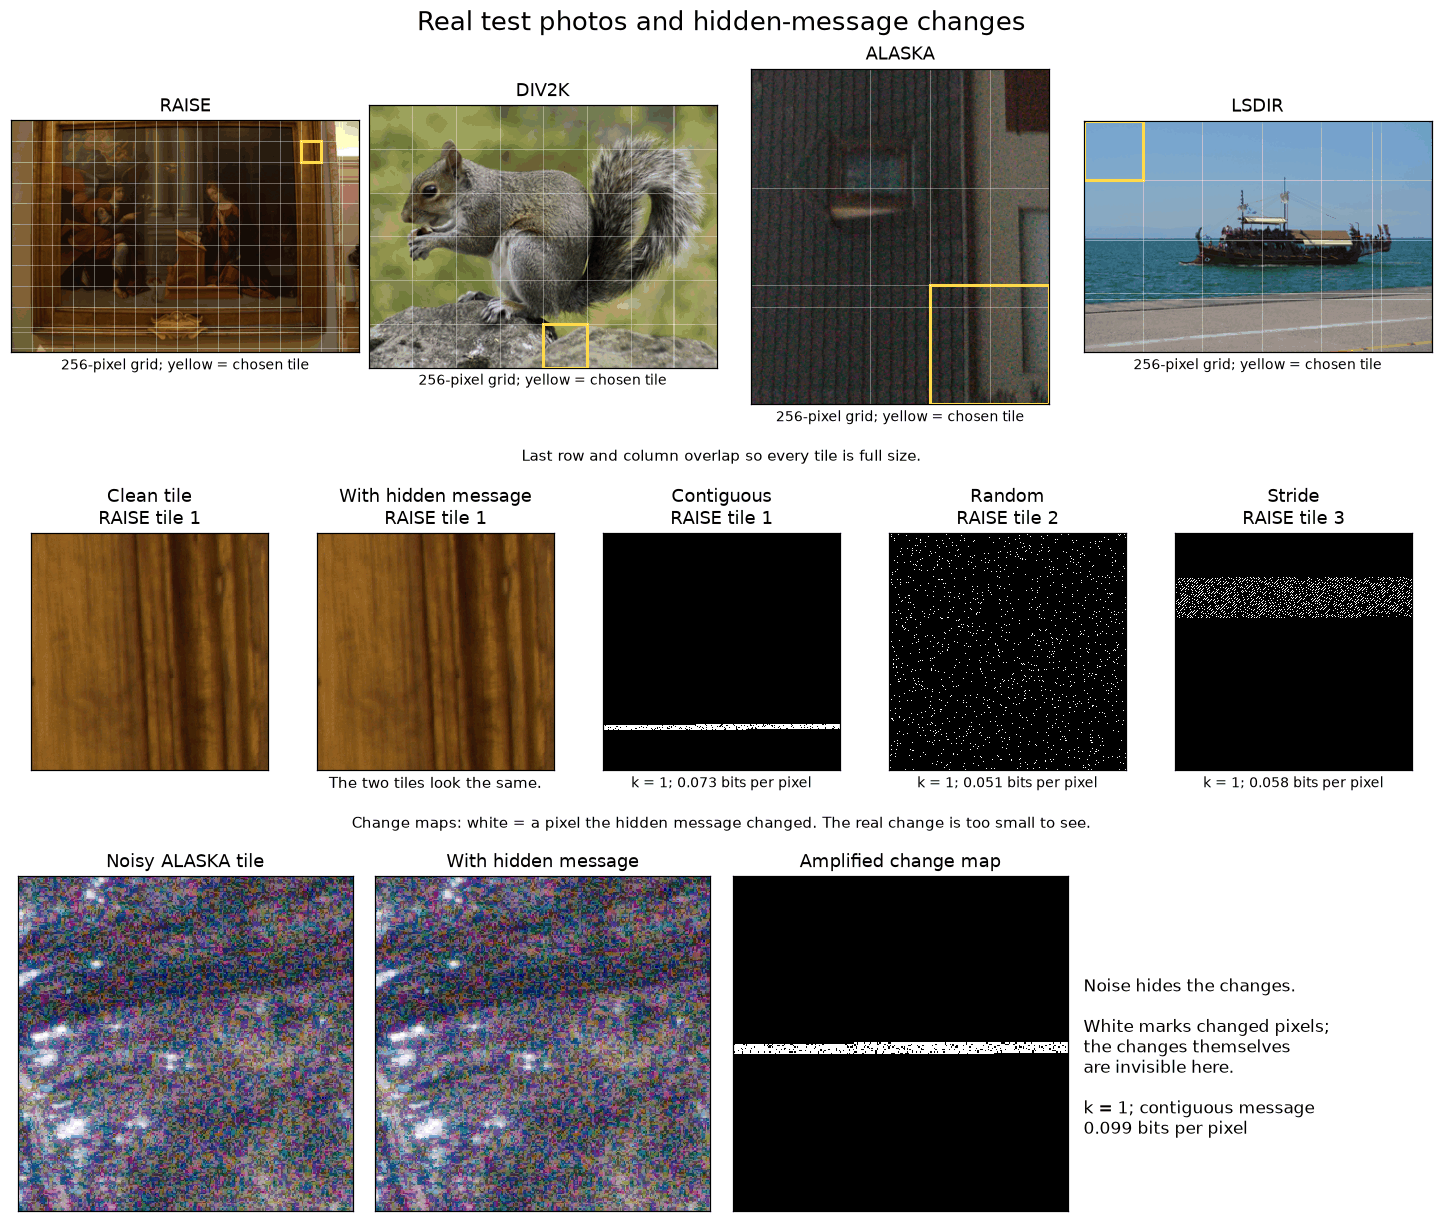

In [3]:
from IPython.display import display, Image
display(Image(data=(ROOT/'docs/figures/report/data-sample.png').read_bytes()))

## 0. How good is this model, in short?
A **false alarm** calls a clean image a hidden message. A **miss** fails to detect a hidden message. **Overall error** is the average of those two rates. **AUC** measures how often a hidden-message image scores above a clean image (ties count half); it runs from 0 to 1.

In [4]:
headline(report)

- **Standard test:** 2.2% overall error (about 1 in 46 wrong).
- **ALASKA (cameras seen in training):** 17.5% overall error (about 1 in 6 wrong).
- **ALASKA (cameras not seen in training):** 15.4% overall error (about 1 in 7 wrong).
- **LSDIR:** 7.8% overall error (about 1 in 13 wrong).
- **Standard-test AUC:** 0.997 (0 to 1).

Threshold set after training. One saved cut-off is used throughout.

## 1. What was trained?

In [5]:
run_card(report, reference)

- **Model:** xunet wide gapcov32
- **Front end:** Rich residual filters (SRM)
- **Epochs:** 50
- **Training tile:** 256 pixels
- **Training sources:** RAISE 40%, LSDIR 20%, ALASKA 40%

No reference model supplied.

## 2. Did training go well?
These are the saved checkpoint-selection curves, not the later threshold-calibration results. The chart names the original validation.

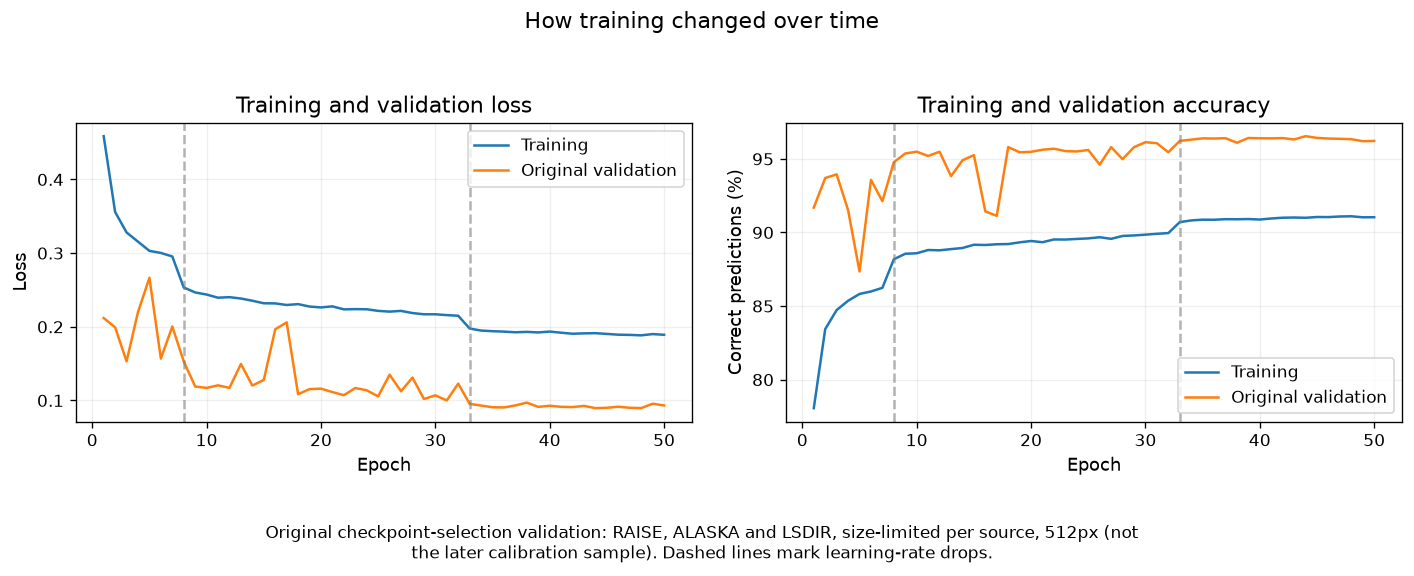

In [6]:
training_plots(report)

## 3. Where does it fail?
All bars use this model’s one saved validation cut-off.

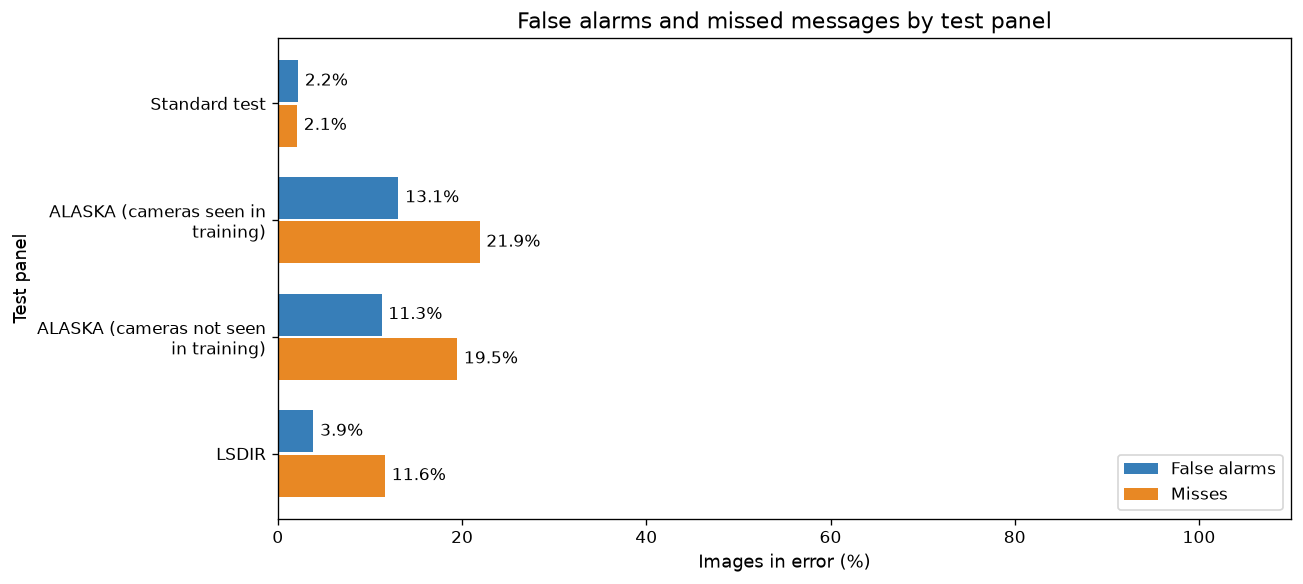

In [7]:
panel_plot(report)

## 4. Which hidden messages does it miss?
**k** is embedding strength: the number of low-order bits available for hiding a message. **bpp** is the requested message size in bits per pixel. Grid bins are 0.05–0.10, 0.10–0.15, 0.15–0.35 and 0.35–0.50 bpp (last upper edge included). Higher-strength results, if saved, are in the appendix.

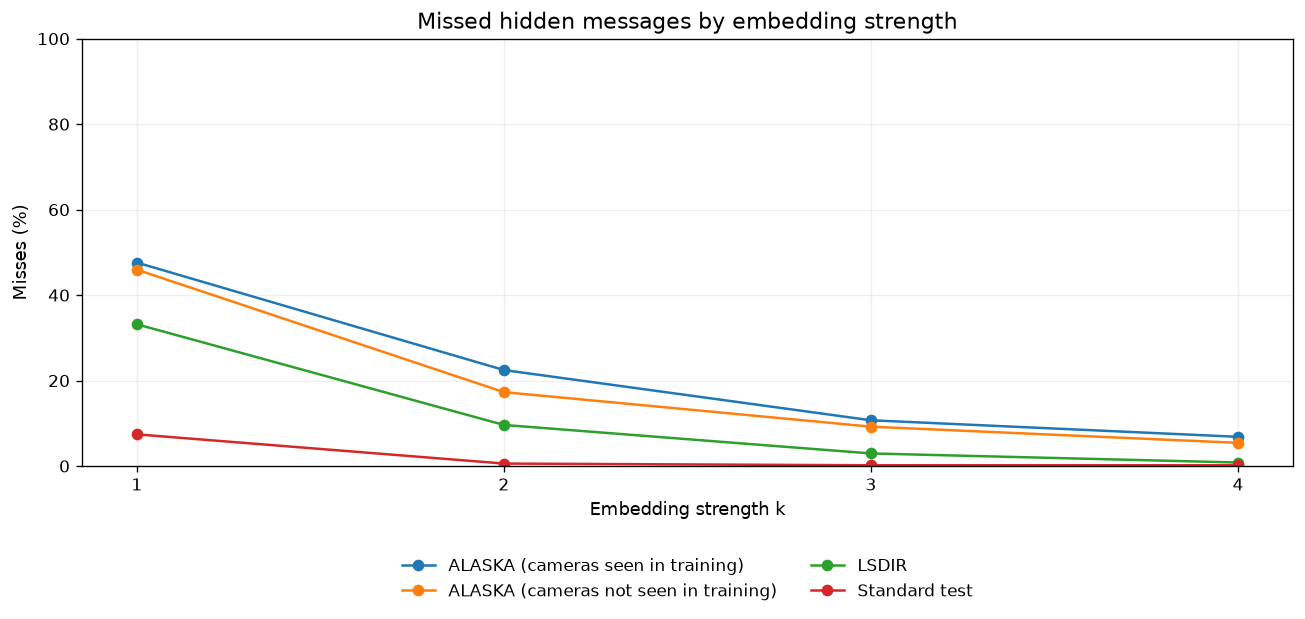

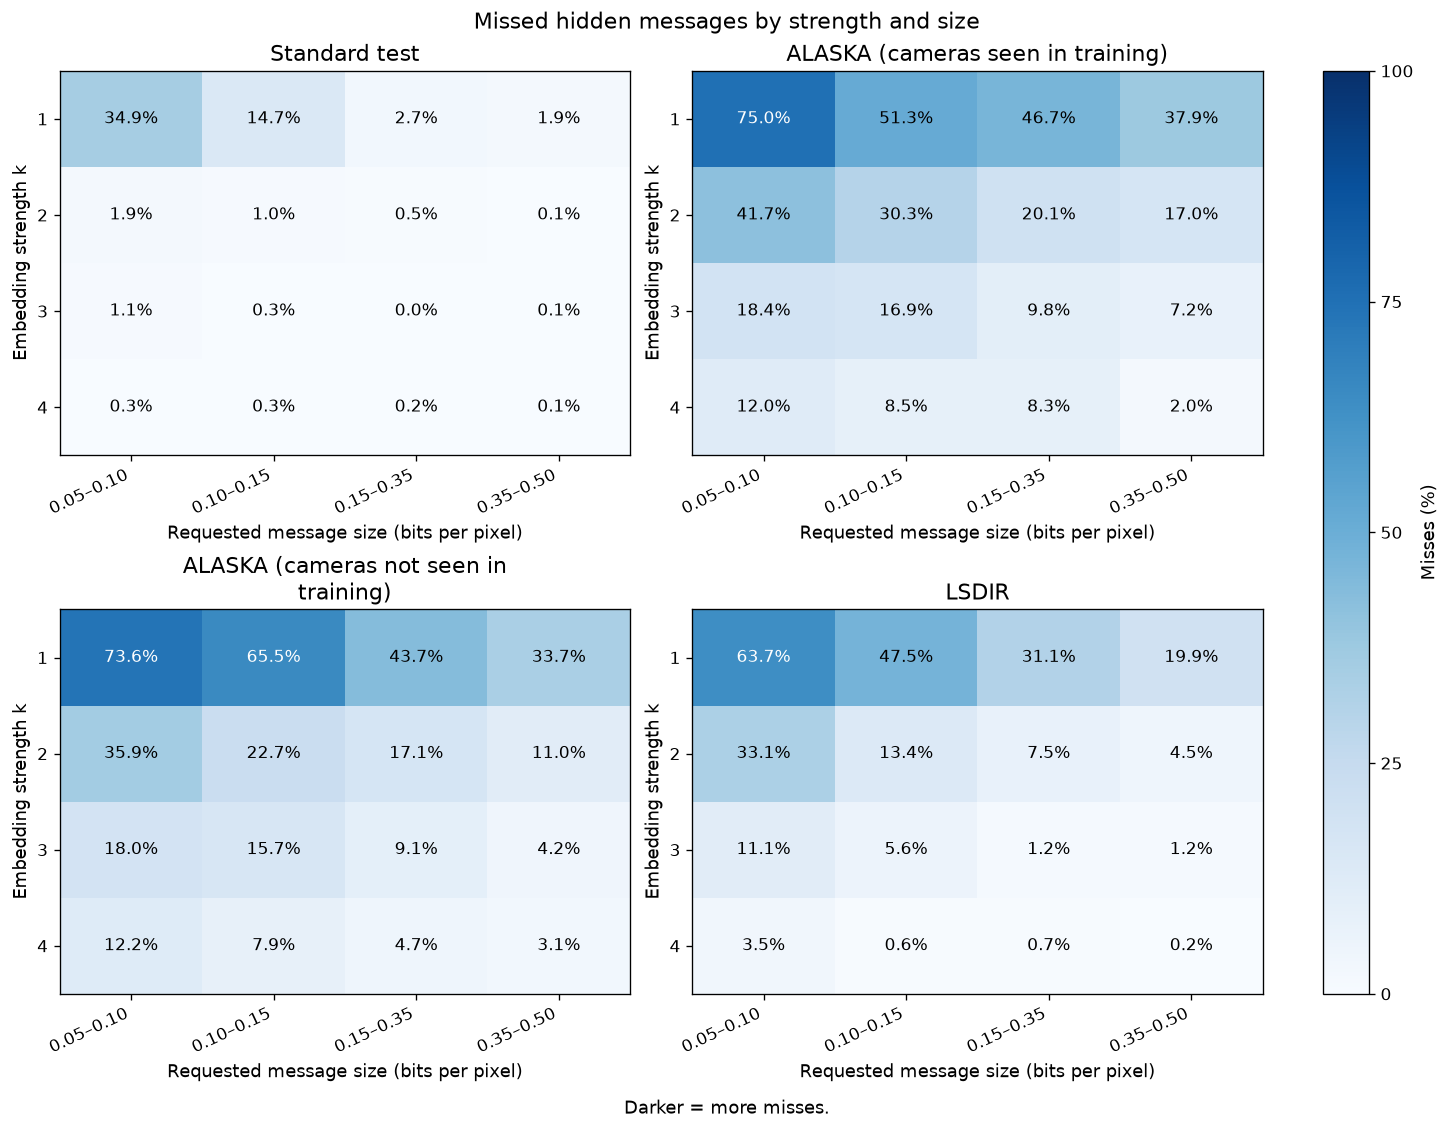

In [8]:
miss_tables = miss_plots(report)

## 5. Does it break on hard images?
“Small message” means 0.05–0.15 bpp; “noisy” uses the frozen high-noise selection. Error bars are saved Wilson 95% ranges for tiles/pairs, not ranges grouped by photo. Cells can share images.

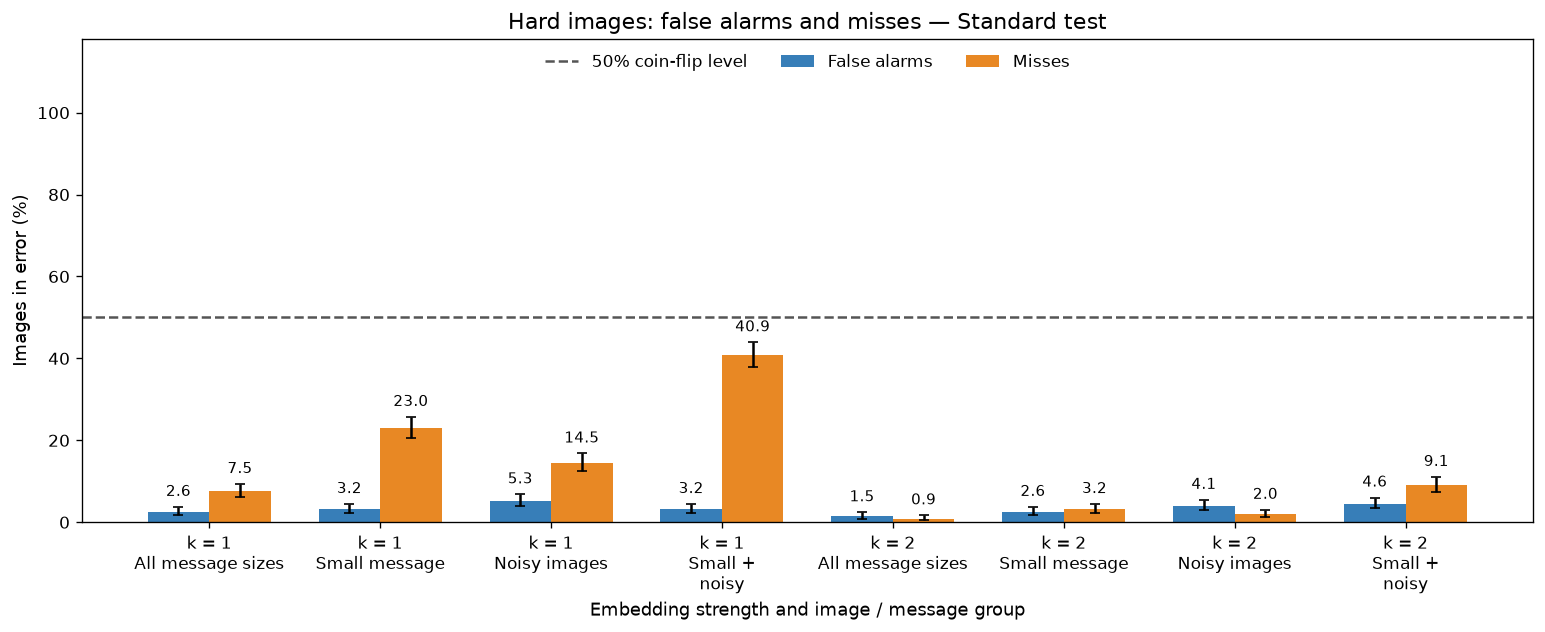

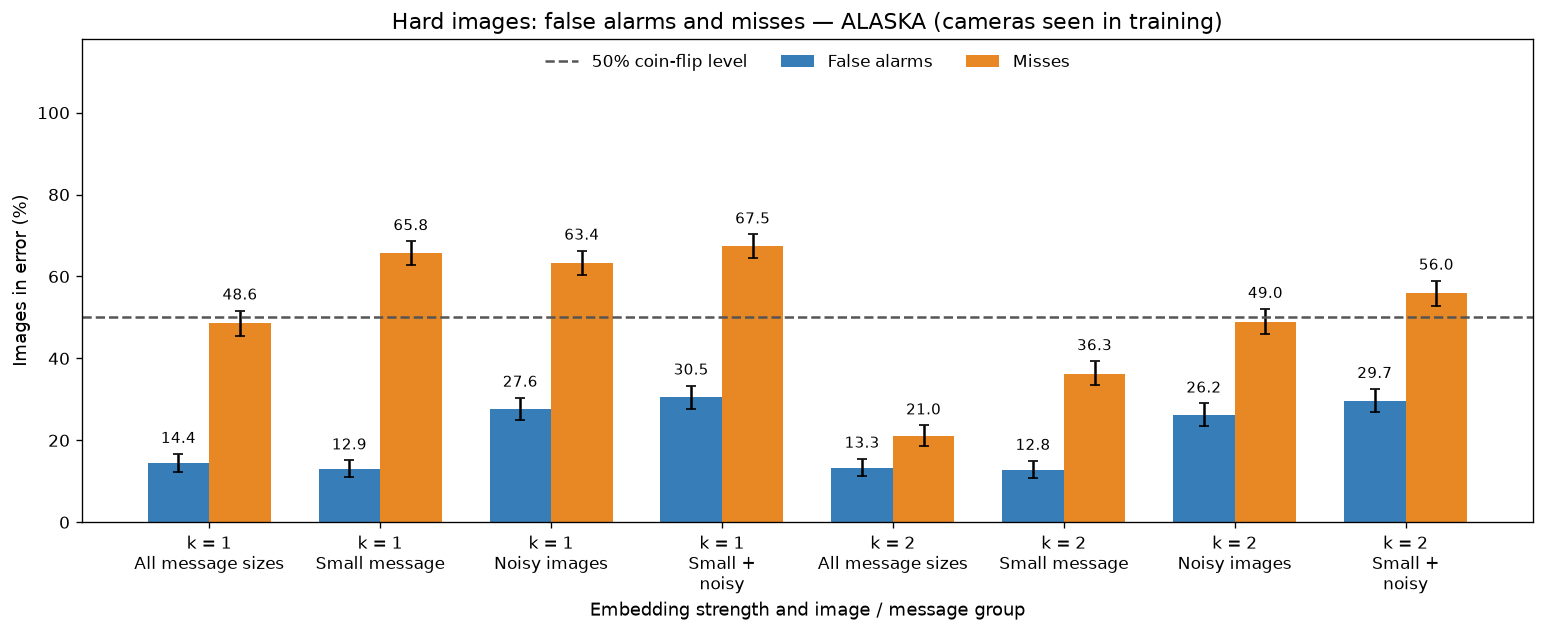

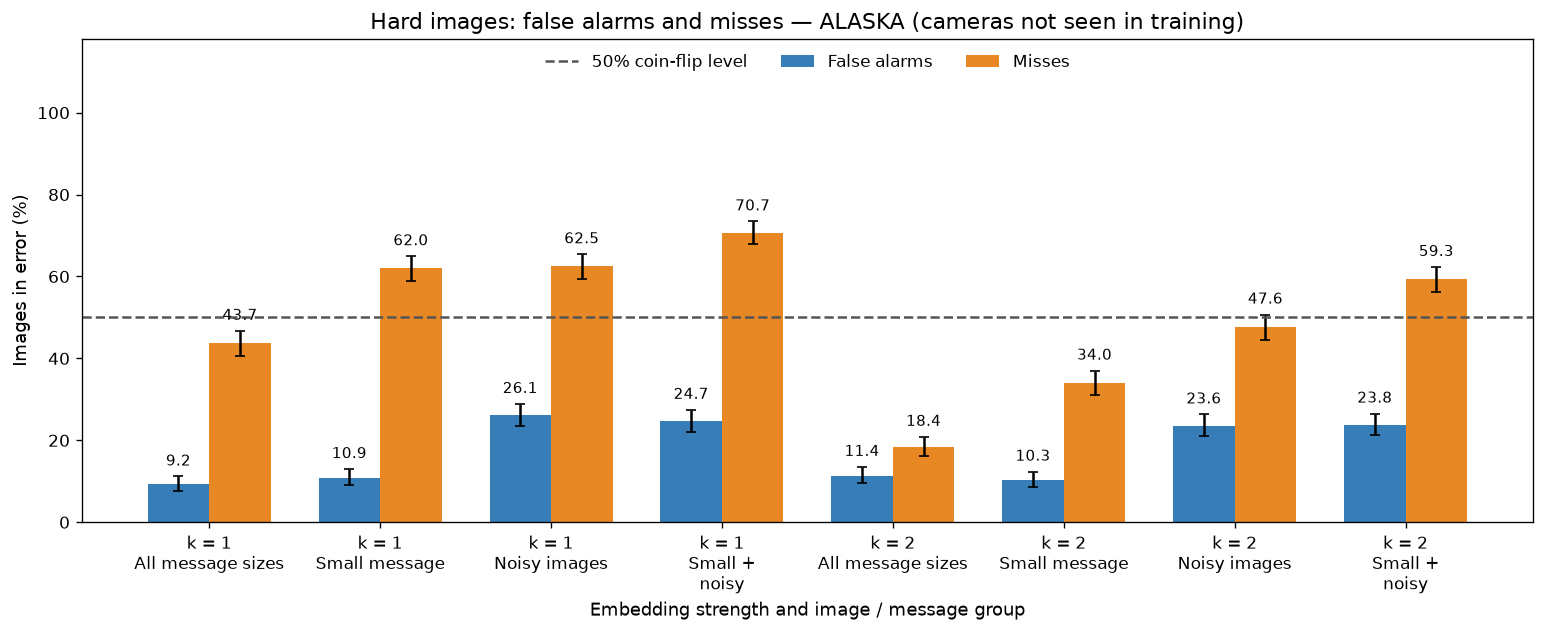

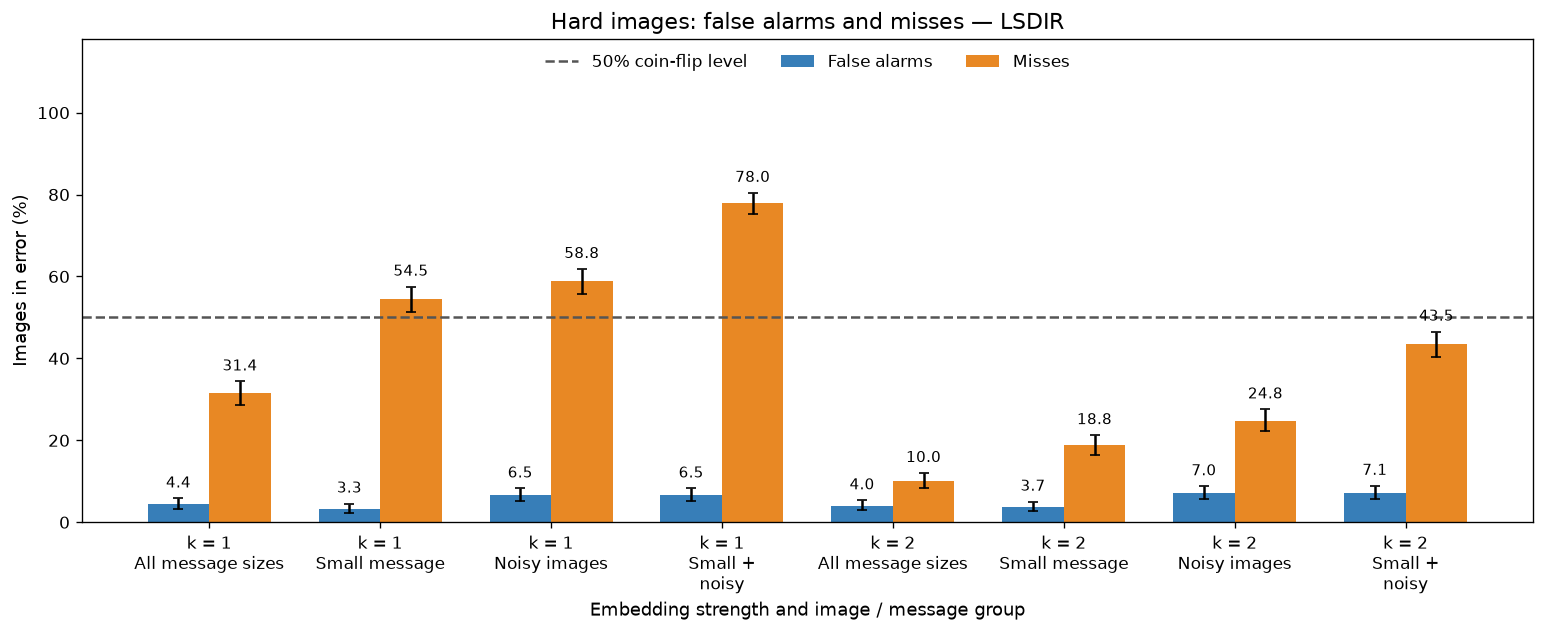

In [9]:
hard_plots(report)

## 6. Better or worse than the reference?
Values are percentage-point differences, not relative percentages. Each model keeps its own saved validation cut-off. Only identical frozen test recipes are compared.

In [10]:
comparison_plot(report, reference)

No reference model supplied; comparison skipped.

## 7. Would knowing the source help?
Reference only: source-specific cut-offs are not the deployment policy. There is no DIV2K or mixed-source reference. ALASKA shares one source-specific cut-off across both camera groups.

In [11]:
source_lines(report)

- **RAISE:** 1.6% → 1.7% overall error if the source were known.
- **ALASKA:** cameras seen in training: 17.5% → 17.6%; cameras not seen in training: 15.4% → 15.3% overall error if the source were known.
- **LSDIR:** 7.8% → 7.7% overall error if the source were known.

## Where in the tile? (cell heatmap)

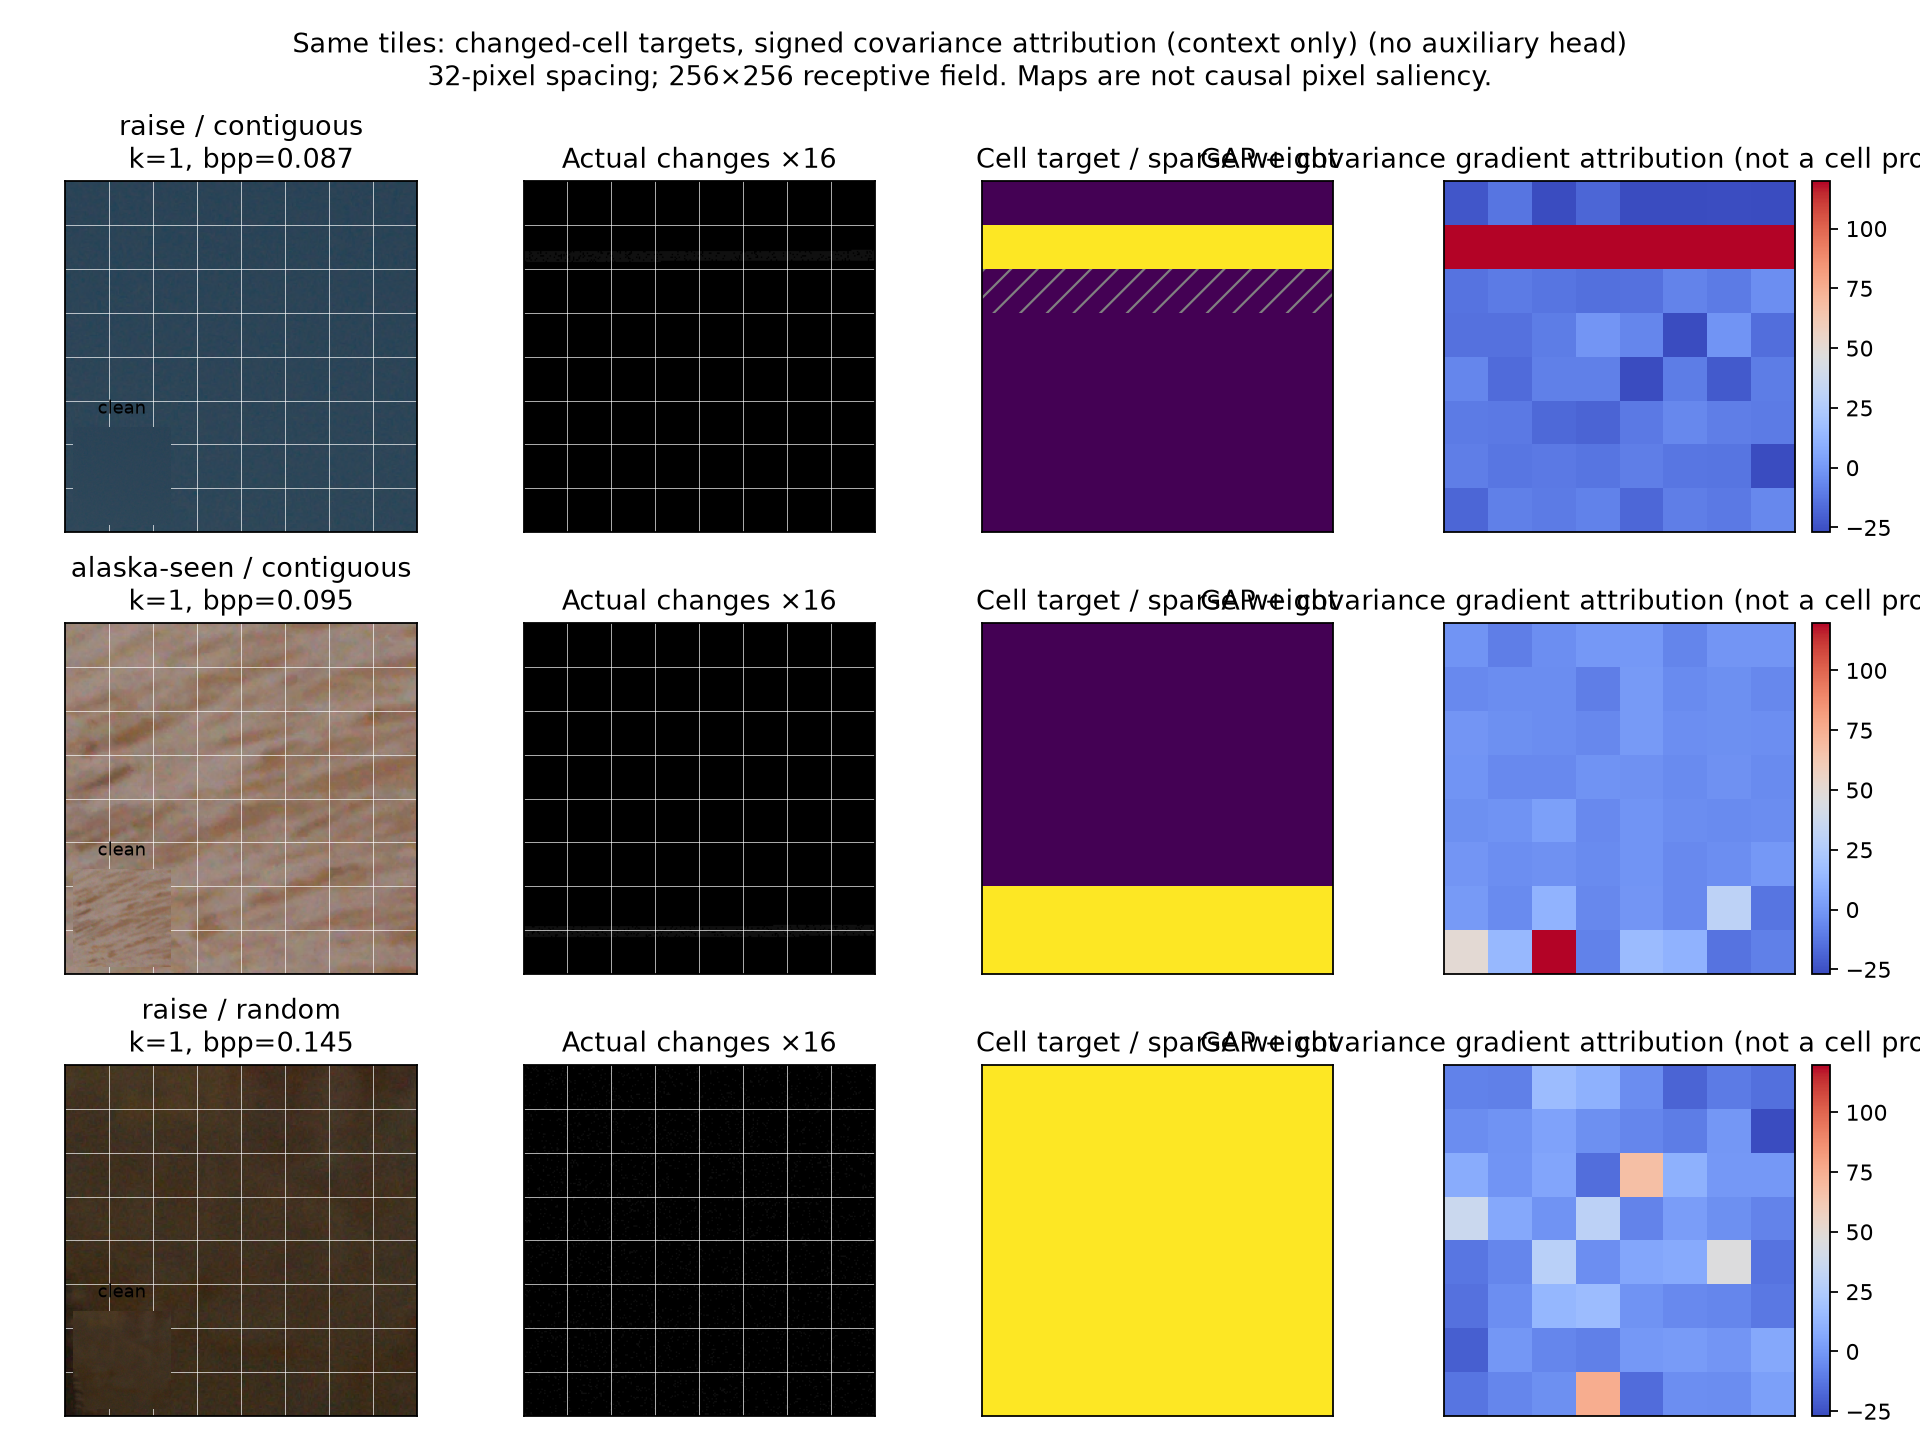

Test panel,This model: attribution,Reference: cell head,Reference: CAM
All panels,"0.752 [0.718, 0.786]","0.867 [0.838, 0.893]","0.811 [0.774, 0.846]"
RAISE,"0.950 [0.923, 0.974]","0.972 [0.948, 0.990]","0.972 [0.950, 0.989]"
ALASKA (cameras seen in training),"0.639 [0.599, 0.680]","0.813 [0.748, 0.865]","0.731 [0.660, 0.791]"
ALASKA (cameras not seen in training),"0.694 [0.627, 0.761]","0.826 [0.766, 0.881]","0.763 [0.691, 0.833]"
LSDIR,"0.724 [0.657, 0.790]","0.858 [0.804, 0.904]","0.778 [0.699, 0.848]"


AUC and 95% photo-bootstrap intervals compare changed and valid unchanged cells **within each contiguous message tile**, then average the tile AUCs. The cell head was trained with changed-cell targets and sees a 48×48-pixel patch per square. CAM applies the tile-scoring layer at each grid location. Attribution is worked out afterwards from the tile score and depends on the whole 256×256 tile. Squares are 32 pixels apart; these are not exact causal pixel maps.

Reference columns come from its own saved run on the same frozen tiles. They are shown side by side; this is not a paired test.

Map,Patch seen,Cell cut-off,Validation false alarms,Test false alarms,Test recall
This model: attribution,256×256 (whole tile),11.117,5.0%,4.7%,14.7%
Reference: cell head,48×48,0.197,5.0%,4.2%,16.1%
Reference: CAM,48×48,7.109,5.0%,3.9%,16.6%


Each map uses its own validation cut-off, at at most 5% false alarms. Test rates include clean partners and valid unchanged message cells; recall is the fraction of changed cells above the cut-off and includes contiguous and scattered random messages.

In [12]:
from cvdl.report_cells import show_cell_report
show_cell_report(CELL_DIR, CELL_REFERENCE_DIR)
assert 'torch' not in sys.modules

## 8. Author notes
- **What changed?** [Pending: author]
- **What do the saved results show?** [Pending: cite charts or appendix rows]
- **What remains weak?** [Pending: author]
- **How does the reference compare?** [Pending / not supplied]
- **Limits:** [Pending: source mix, image sizes, shared photos, changed test protocols]
- **Next decision:** [Pending: author]

No interpretation is generated. Old 512-pixel / k1–8 results are not like-for-like with the balanced 256-pixel / k1–4 suite.

## Appendix — lookup only
Rates are rounded to one decimal, AUC and cut-offs to three decimals. Test-optimised and fixed-0.500 results are diagnostics, not deployment results. Saved files keep full precision.

In [13]:
appendix(report, reference)

Test panel,Group,Subset,Image pairs,Images,Photos,Distinct clean tiles,AUC,Validation cut-off,False alarms %,Misses %,Overall error %
Standard test,All images,All message sizes,10944,21888,249,10944,0.997,0.491,2.2%,2.1%,2.2%
Standard test,Source,DIV2K,1248,2496,100,1248,0.986,0.491,7.6%,4.8%,6.2%
Standard test,Source,RAISE,9696,19392,149,9696,0.998,0.491,1.5%,1.7%,1.6%
Standard test,Embedding strength,1,2736,5472,247,2736,0.991,0.491,1.9%,7.4%,4.6%
Standard test,Embedding strength,2,2736,5472,246,2736,1.000,0.491,2.3%,0.6%,1.5%
Standard test,Embedding strength,3,2736,5472,248,2736,1.000,0.491,2.2%,0.2%,1.2%
Standard test,Embedding strength,4,2736,5472,248,2736,1.000,0.491,2.4%,0.2%,1.3%
Standard test,Source and strength,"DIV2K, k = 1",312,624,98,312,0.953,0.491,6.1%,16.3%,11.2%
Standard test,Source and strength,"DIV2K, k = 2",312,624,97,312,0.995,0.491,9.0%,2.2%,5.6%
Standard test,Source and strength,"DIV2K, k = 3",312,624,99,312,0.999,0.491,7.1%,0.3%,3.7%


In [14]:
assert os.environ['CUDA_VISIBLE_DEVICES'] == '' and os.environ['HIP_VISIBLE_DEVICES'] == ''
assert 'torch' not in sys.modules
import socket
try:
    socket.getaddrinfo('external-network.invalid', 443)
except PermissionError:
    pass
else:
    raise AssertionError('external network guard missing')